In [60]:
import requests, json
import pandas as pd

In [61]:
response = requests.get(url="https://dst-de.s3.eu-west-3.amazonaws.com/extract_async.json")

In [62]:
response.json()

{'employees': [{'id': 0,
   'personal': {'first_name': 'Лин',
    'last_name': 'Василькова',
    'email': 'линвасилькова@apple.ru',
    'country': 'Russia',
    'age': 27,
    'gender': 'F',
    'marital_status': 'Married'},
   'company': {'name': 'Apple',
    'num_employees': 154000,
    'benefits': 'Health insurance, stock options, employee discounts, paid time off, on-site fitness centers',
    'main_area_of_expertise': 'Consumer Electronics, Software',
    'headquarters': 'Cupertino, California, USA'},
   'job': {'salary': 68000,
    'department': 'Marketing',
    'join_date': '2023-07-12',
    'position_level': 'Junior',
    'performance_score': 3,
    'last_promotion_date': '2023-07-23'},
   'experience': {'experience_years': 1,
    'has_certifications': False,
    'education_level': 'PhD',
    'work_hours_per_week': 28,
    'projects_completed': 17}},
  {'id': 1,
   'personal': {'first_name': 'Gina',
    'last_name': 'Schober',
    'email': 'gina.schober@facebook.de',
    'count

In [63]:
def telecharger_dataset(url : str) :
    try:
        r = requests.get(url= url, timeout=20)
        r.raise_for_status()              # lève HTTPError si 4xx/5xx
    except requests.exceptions.HTTPError as e:
        print(f"\nErreur HTTP : {e}")
    except requests.exceptions.ConnectionError:
        print("Erreur de connexion")
    except requests.exceptions.Timeout:
        print("Timeout")
    return r.json()

In [64]:
dataset = telecharger_dataset("https://dst-de.s3.eu-west-3.amazonaws.com/extract_async.json")

In [65]:
def explorer_json(obj, indent=0, racine :str = "employees"):
    prefix = "  " * indent
    if isinstance(obj, dict):
        for k, v in obj.items():
            print(f"{prefix}[dict] {k}: {type(v).__name__}")
            explorer_json(obj=v, indent=indent + 1)
    elif isinstance(obj, list):
        print(f"{prefix}[liste de {len(obj)} éléments]")
        for k, v in obj[0].items():
            print(f"{prefix}[dict] {k}: {type(v).__name__}")
            explorer_json(obj=v, indent=indent + 1)
    else:
        print(f"{prefix}→ {repr(obj)}")


In [66]:
explorer_json(obj=dataset)

[dict] employees: list
  [liste de 50000 éléments]
  [dict] id: int
    → 0
  [dict] personal: dict
    [dict] first_name: str
      → 'Лин'
    [dict] last_name: str
      → 'Василькова'
    [dict] email: str
      → 'линвасилькова@apple.ru'
    [dict] country: str
      → 'Russia'
    [dict] age: int
      → 27
    [dict] gender: str
      → 'F'
    [dict] marital_status: str
      → 'Married'
  [dict] company: dict
    [dict] name: str
      → 'Apple'
    [dict] num_employees: int
      → 154000
    [dict] benefits: str
      → 'Health insurance, stock options, employee discounts, paid time off, on-site fitness centers'
    [dict] main_area_of_expertise: str
      → 'Consumer Electronics, Software'
    [dict] headquarters: str
      → 'Cupertino, California, USA'
  [dict] job: dict
    [dict] salary: int
      → 68000
    [dict] department: str
      → 'Marketing'
    [dict] join_date: str
      → '2023-07-12'
    [dict] position_level: str
      → 'Junior'
    [dict] performance_sc

In [67]:
dataset_employees = dataset["employees"]

In [68]:
df = pd.json_normalize(dataset_employees)

In [69]:
df.describe()

,id,personal.age,company.num_employees,job.salary,job.performance_score,experience.experience_years,experience.work_hours_per_week,experience.projects_completed
count,50000.000000,50000.00000,4.793700e+04,47937.000000,47937.000000,47937.000000,47937.000000,47937.000000
mean,24999.500000,34.66824,3.731355e+05,74423.409892,5.487869,10.522123,40.045602,25.001419
std,14433.901067,23.44951,4.611236e+05,19399.698957,2.861925,11.846434,11.809723,14.695933
min,0.000000,-65.00000,8.648200e+04,0.000000,1.000000,-47.000000,20.000000,0.000000
25%,12499.750000,24.00000,1.540000e+05,70000.000000,3.000000,2.000000,30.000000,12.000000
50%,24999.500000,38.00000,1.565000e+05,77000.000000,5.000000,8.000000,40.000000,25.000000
75%,37499.250000,52.00000,1.810000e+05,84000.000000,8.000000,18.000000,50.000000,38.000000
max,49999.000000,65.00000,1.298000e+06,123000.000000,10.000000,47.000000,60.000000,50.000000


In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              50000 non-null  int64  
 1   personal.first_name             50000 non-null  str    
 2   personal.last_name              50000 non-null  str    
 3   personal.email                  50000 non-null  str    
 4   personal.country                50000 non-null  str    
 5   personal.age                    50000 non-null  int64  
 6   personal.gender                 50000 non-null  str    
 7   personal.marital_status         47937 non-null  str    
 8   company.name                    47937 non-null  str    
 9   company.num_employees           47937 non-null  float64
 10  company.benefits                47937 non-null  str    
 11  company.main_area_of_expertise  47937 non-null  str    
 12  company.headquarters            47937 non-n

In [71]:
missing = pd.DataFrame(data={"nb manquants": df.isna().sum(), "% manquant": df.isna().mean().mul(other=100).round(decimals=3)})
missing[missing["nb manquants"] > 0].sort_values(by="nb manquants", ascending=False)

,nb manquants,% manquant
job.last_promotion_date,4393,8.786
personal.marital_status,2063,4.126
company.num_employees,2063,4.126
company.name,2063,4.126
company.main_area_of_expertise,2063,4.126
company.headquarters,2063,4.126
job.salary,2063,4.126
company.benefits,2063,4.126
job.department,2063,4.126
job.join_date,2063,4.126


In [72]:
df[df.isna().any(axis=1)]

,id,personal.first_name,personal.last_name,personal.email,personal.country,personal.age,personal.gender,personal.marital_status,company.name,company.num_employees,...,job.department,job.join_date,job.position_level,job.performance_score,job.last_promotion_date,experience.experience_years,experience.has_certifications,experience.education_level,experience.work_hours_per_week,experience.projects_completed
1,1,Gina,Schober,gina.schober@facebook.de,Germany,59,F,Divorced,Facebook,86482.0,...,Sales,2014-03-01,Mid,2.0,NaN,24.0,True,Bachelor's,42.0,23.0
7,7,Сука,Салимов,сука.салимов@apple.ru,Russia,43,M,Single,Apple,154000.0,...,Finance,2008-10-16,Junior,3.0,NaN,19.0,True,Master's,27.0,42.0
65,65,Ke,Salaris,ke.salaris@gmail.com,Italy,16,M,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,High School,NaN,NaN
76,76,Heiðrún,Hasling,hhasling@hotmail.com,Denmark,17,F,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,High School,NaN,NaN
82,82,Banfi,Matsangos,bmatsangos@apple.cy,Cyprus,57,M,Divorced,Apple,154000.0,...,Finance,1995-02-18,Mid,10.0,NaN,35.0,False,Master's,43.0,47.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49970,49970,Mirvari,Hafizov,mirvarihafizov@amazon.az,Azerbaijan,37,F,Married,Amazon,1298000.0,...,Support,2023-05-14,Junior,2.0,NaN,3.0,False,PhD,25.0,13.0
49972,49972,Mahvash,Norlander,mahvashnorlander@apple.se,Sweden,25,F,Single,Apple,154000.0,...,Finance,2023-09-18,Senior,1.0,NaN,0.0,False,Master's,52.0,9.0
49975,49975,Амик,Исраилова,амик.и@microsoft.ru,Russia,19,M,Divorced,Microsoft,181000.0,...,Finance,2023-07-08,Mid,2.0,NaN,1.0,False,Master's,43.0,3.0
49983,49983,Sabeth,Fehrenbach,sfehrenbach@google.de,Germany,51,F,Divorced,Google,156500.0,...,Engineering,2023-07-27,Senior,6.0,NaN,0.0,False,PhD,32.0,28.0


In [73]:
df.nunique()

id                                50000
personal.first_name               35633
personal.last_name                32435
personal.email                    42439
personal.country                     36
personal.age                        101
personal.gender                       6
personal.marital_status               4
company.name                          5
company.num_employees                 5
company.benefits                      5
company.main_area_of_expertise        5
company.headquarters                  5
job.salary                           70
job.department                        6
job.join_date                     10717
job.position_level                    3
job.performance_score                10
job.last_promotion_date            8972
experience.experience_years          95
experience.has_certifications         2
experience.education_level            5
experience.work_hours_per_week       41
experience.projects_completed        51
dtype: int64

In [74]:
import matplotlib.pyplot as plt

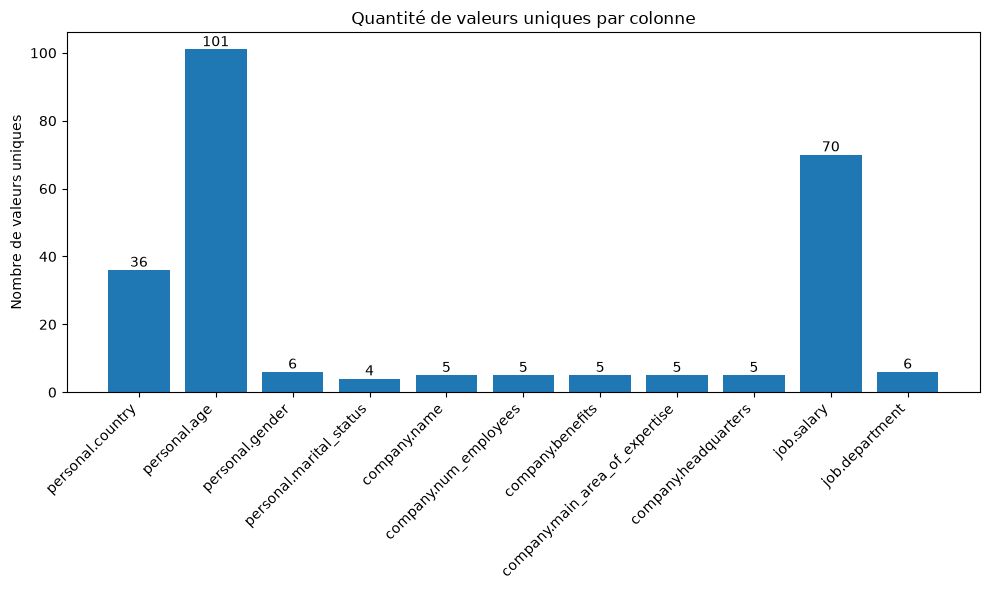

In [77]:
COLONNES = [
"personal.country",
"personal.age",
"personal.gender",
"personal.marital_status",
"company.name",
"company.num_employees",
"company.benefits",
"company.main_area_of_expertise",
"company.headquarters",
"job.salary",
"job.department"]

counts = df[COLONNES].nunique()

plt.figure(figsize=(10, 6))
bars = plt.bar(counts.index, counts.values)
plt.bar_label(bars)                      # affiche la valeur au-dessus de chaque barre
plt.xticks(rotation=45, ha='right')
plt.ylabel('Nombre de valeurs uniques')
plt.title('Quantité de valeurs uniques par colonne')
plt.tight_layout()
plt.show()

In [80]:
df['job.department'].value_counts()

job.department
HR             8099
Finance        8080
Engineering    8018
Sales          7965
Marketing      7937
Support        7838
Name: count, dtype: int64

In [18]:
df = df.dropna(subset=['personal.country','personal.gender', 'personal.marital_status', 'company.name', 'company.num_employees','company.benefits','company.main_area_of_expertise','company.headquarters','job.department'])

In [19]:
df.info()

<class 'pandas.DataFrame'>
Index: 47937 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              47937 non-null  int64  
 1   personal.first_name             47937 non-null  str    
 2   personal.last_name              47937 non-null  str    
 3   personal.email                  47937 non-null  str    
 4   personal.country                47937 non-null  str    
 5   personal.age                    47937 non-null  int64  
 6   personal.gender                 47937 non-null  str    
 7   personal.marital_status         47937 non-null  str    
 8   company.name                    47937 non-null  str    
 9   company.num_employees           47937 non-null  float64
 10  company.benefits                47937 non-null  str    
 11  company.main_area_of_expertise  47937 non-null  str    
 12  company.headquarters            47937 non-null  

<Axes: xlabel='personal.age', ylabel='Count'>

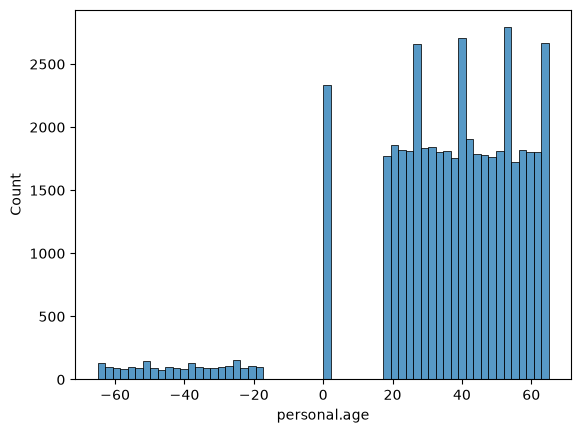

In [20]:
import seaborn as sns
sns.histplot(data=df["personal.age"], bins=60)

In [21]:
df.describe()

,id,personal.age,company.num_employees,job.salary,job.performance_score,experience.experience_years,experience.work_hours_per_week,experience.projects_completed
count,47937.000000,47937.000000,4.793700e+04,47937.000000,47937.000000,47937.000000,47937.000000,47937.000000
mean,24986.174667,35.551724,3.731355e+05,74423.409892,5.487869,10.522123,40.045602,25.001419
std,14427.456927,23.498592,4.611236e+05,19399.698957,2.861925,11.846434,11.809723,14.695933
min,0.000000,-65.000000,8.648200e+04,0.000000,1.000000,-47.000000,20.000000,0.000000
25%,12489.000000,26.000000,1.540000e+05,70000.000000,3.000000,2.000000,30.000000,12.000000
50%,24978.000000,39.000000,1.565000e+05,77000.000000,5.000000,8.000000,40.000000,25.000000
75%,37481.000000,52.000000,1.810000e+05,84000.000000,8.000000,18.000000,50.000000,38.000000
max,49999.000000,65.000000,1.298000e+06,123000.000000,10.000000,47.000000,60.000000,50.000000


In [22]:
df["personal.age"] = df["personal.age"].abs()

In [23]:
df = df[df["personal.age"] >= 20]

In [24]:
df.describe()

,id,personal.age,company.num_employees,job.salary,job.performance_score,experience.experience_years,experience.work_hours_per_week,experience.projects_completed
count,43734.000000,43734.000000,4.373400e+04,43734.000000,43734.000000,43734.000000,43734.000000,43734.000000
mean,24964.963438,42.421366,3.730896e+05,74608.839804,5.493666,10.977272,40.073787,25.010198
std,14417.681210,13.281141,4.612035e+05,19426.255501,2.860861,11.892282,11.812732,14.699209
min,0.000000,20.000000,8.648200e+04,0.000000,1.000000,-47.000000,20.000000,0.000000
25%,12495.250000,31.000000,1.540000e+05,71000.000000,3.000000,3.000000,30.000000,12.000000
50%,24953.500000,42.000000,1.565000e+05,77000.000000,5.000000,9.000000,40.000000,25.000000
75%,37439.500000,54.000000,1.810000e+05,84000.000000,8.000000,18.000000,50.000000,38.000000
max,49998.000000,65.000000,1.298000e+06,123000.000000,10.000000,47.000000,60.000000,50.000000


<Axes: xlabel='experience.experience_years', ylabel='Count'>

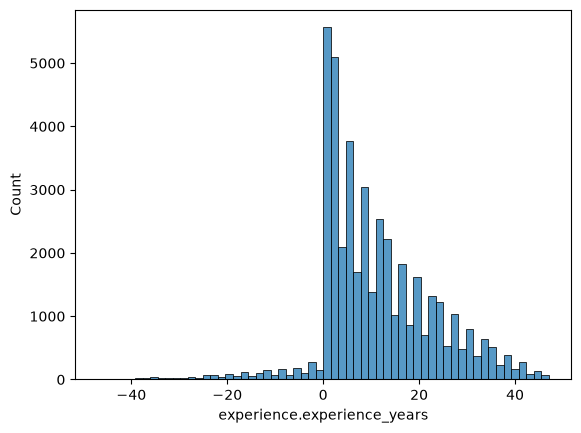

In [25]:
import seaborn as sns
sns.histplot(data=df["experience.experience_years"], bins=60)

In [26]:
df = df[df["experience.experience_years"] >= 0]

In [27]:
df.describe()

,id,personal.age,company.num_employees,job.salary,job.performance_score,experience.experience_years,experience.work_hours_per_week,experience.projects_completed
count,41677.000000,41677.000000,4.167700e+04,41677.000000,41677.000000,41677.000000,41677.000000,41677.000000
mean,24997.758836,42.361014,3.727022e+05,74624.733066,5.496317,12.165631,40.049716,25.030448
std,14413.670283,13.289108,4.609136e+05,19399.687984,2.861911,10.627820,11.814176,14.698400
min,0.000000,20.000000,8.648200e+04,0.000000,1.000000,0.000000,20.000000,0.000000
25%,12531.000000,31.000000,1.540000e+05,71000.000000,3.000000,3.000000,30.000000,12.000000
50%,24975.000000,42.000000,1.565000e+05,77000.000000,6.000000,9.000000,40.000000,25.000000
75%,37482.000000,54.000000,1.810000e+05,84000.000000,8.000000,19.000000,50.000000,38.000000
max,49998.000000,65.000000,1.298000e+06,123000.000000,10.000000,47.000000,60.000000,50.000000


In [28]:
df.to_csv('fin_exploration.csv')

In [30]:
def clean_columns(df, sep='.'):
    """Retourne une copie du DataFrame avec les points remplacés par _ dans les noms de colonnes."""
    df = df.copy()
    df.columns = [c.replace(sep, '_') if isinstance(c, str) else c for c in df.columns]
    return df

In [33]:
df = clean_columns(df)

In [34]:
df.info()

<class 'pandas.DataFrame'>
Index: 41677 entries, 0 to 49998
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              41677 non-null  int64  
 1   personal_first_name             41677 non-null  str    
 2   personal_last_name              41677 non-null  str    
 3   personal_email                  41677 non-null  str    
 4   personal_country                41677 non-null  str    
 5   personal_age                    41677 non-null  int64  
 6   personal_gender                 41677 non-null  str    
 7   personal_marital_status         41677 non-null  str    
 8   company_name                    41677 non-null  str    
 9   company_num_employees           41677 non-null  float64
 10  company_benefits                41677 non-null  str    
 11  company_main_area_of_expertise  41677 non-null  str    
 12  company_headquarters            41677 non-null  

In [42]:
df['job'].unique()

<StringArray>
['Marketing', 'Sales', 'HR', 'Support', 'Engineering', 'Finance']
Length: 6, dtype: str

In [ ]:
df_persons = df.loc[:, df.columns.str.startswith("personal_")]

In [58]:
df_persons['personal_gender'].unique()

<StringArray>
['F', 'M', 'female', 'Female', 'Male', 'male']
Length: 6, dtype: str

In [ ]:
df